# 02 &nbsp;Which configurations find the evidence?

Before any answers, a cheaper question: does each configuration put the right text in front of the model? Retrieval scores are what most teams tune, because they are quick to compute. Notebook 04 tests whether they predict answer quality. This notebook measures them.

- **MultiHop-RAG:** the share of a question's evidence sentences that were retrieved (a sentence counts if at least half of it sits in retrieved chunks), and whether all of them were. Only answerable questions have evidence, so the 35 the articles cannot answer are left out here.
- **Natural Questions:** whether a retrieved chunk from the gold Wikipedia page contains a gold answer.

Every configuration retrieves for the same sampled questions, so every comparison below is paired by question, with 95% bootstrap intervals over questions.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="urllib3 v2 only supports OpenSSL")  # old SSL on macOS system Python

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ragdecisions import style
from ragdecisions.data import DATASETS, RESULTS_DIR, ROOT, load_corpus, load_questions
from ragdecisions.grid import CHUNK_SIZES, RETRIEVERS, TOP_K
from ragdecisions.metrics import answer_in_texts
from ragdecisions.stats import bootstrap_means, interval

style.use_style()

retrieval = pd.read_csv(RESULTS_DIR / "retrieval.csv", keep_default_na=False, na_values=[""])  # keep the type "null" as text
mhr = retrieval[(retrieval["dataset"] == "multihop_rag") & (retrieval["type"] != "null")].copy()
nq = retrieval[retrieval["dataset"] == "natural_questions"].copy()
MEASURE = {"multihop_rag": "evidence_recall", "natural_questions": "answer_hit"}
print(f"MultiHop-RAG: {mhr['qid'].nunique()} answerable questions, Natural Questions: {nq['qid'].nunique()} questions")

MultiHop-RAG: 265 answerable questions, Natural Questions: 200 questions


In [2]:
def contrast(table, measure, column, a, b):
    # Paired difference a minus b, averaged over every other setting, with a bootstrap interval over questions.
    per_question = table.groupby(["qid", column])[measure].mean().unstack(column)
    diff = (per_question[a] - per_question[b]).to_numpy()
    low, high = interval(bootstrap_means(diff, seed=0)[:, 0])
    return {"difference": diff.mean(), "low": low, "high": high}


def grid_only(table):
    return table[table["retriever"].isin(RETRIEVERS)]


CONTRASTS = [
    ("Add the reranker", "rerank", True, False),
    ("bge-base instead of keyword search", "retriever", "bge-base", "bm25"),
    ("MiniLM instead of keyword search", "retriever", "minilm", "bm25"),
    ("512-token chunks instead of 128", "chunk", 512, 128),
    ("10 passages instead of 3", "k", 10, 3),
]


def effects(table, measure):
    return pd.DataFrame({label: contrast(grid_only(table), measure, col, a, b)
                         for label, col, a, b in CONTRASTS}).T


def points(x):
    x = round(x * 100, 1)
    return "0.0" if x == 0 else f"{x:+.1f}"


def show_effects(table):
    return table.style.format(lambda x: f"{points(x)} pts")


def dot_plot(table, measure, k, ax, xlabel):
    # One row per retriever and chunk size: hollow without the reranker, filled with it.
    means = table[table["k"] == k].groupby(["chunk", "retriever", "rerank"])[measure].mean()
    y, ticks, labels = 0, [], []
    for size in CHUNK_SIZES:
        ax.text(-0.01, y - 0.75, f"{size}-token chunks", transform=ax.get_yaxis_transform(), ha="right",
                color=style.INK, fontsize=10.5, fontweight="bold")
        for key in RETRIEVERS:
            off, on = means[size, key, False], means[size, key, True]
            color = style.RETRIEVER_COLORS[key]
            ax.plot([off, on], [y, y], color=color, lw=2, alpha=0.5, zorder=2)
            ax.scatter(off, y, s=70, facecolor=style.SURFACE, edgecolor=color, lw=2, zorder=3)
            ax.scatter(on, y, s=70, color=color, zorder=3)
            ticks.append(y)
            labels.append(style.RETRIEVER_LABELS[key])
            y += 1
        y += 1.2
    ax.set_yticks(ticks, labels)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel(xlabel)
    ax.scatter([], [], s=70, facecolor=style.SURFACE, edgecolor=style.INK_2, lw=2, label="no reranker")
    ax.scatter([], [], s=70, color=style.INK_2, label="with reranker")
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)


def effect_plot(table, ax, xlabel):
    rows = table.iloc[::-1]
    y = np.arange(len(rows))
    best = rows["difference"].abs().idxmax()
    for i, (label, r) in enumerate(rows.iterrows()):
        color = style.HIGHLIGHT if label == best else style.INK_2
        ax.plot([r["low"] * 100, r["high"] * 100], [i, i], color=color, lw=2.5, alpha=0.7)
        ax.scatter(r["difference"] * 100, i, color=color, s=60, zorder=3)
        ax.text(r["high"] * 100 + 0.6, i, f"{r['difference'] * 100:+.1f}", va="center", color=color, fontsize=10)
    ax.axvline(0, color=style.BASELINE, lw=1.2)
    ax.set_yticks(y, rows.index)
    ax.set_xlabel(xlabel)

## 1. MultiHop-RAG: the reranker matters most, and keyword search is hard to beat

The chart shows evidence found with five passages in the prompt, the middle setting. Each line runs from a configuration without the reranker (hollow) to the same one with it (filled).

Keyword search finds the most evidence at every chunk size without the reranker: True
Spread between best and worst retriever, average over chunk sizes: 12.5% without the reranker, 3.7% with it


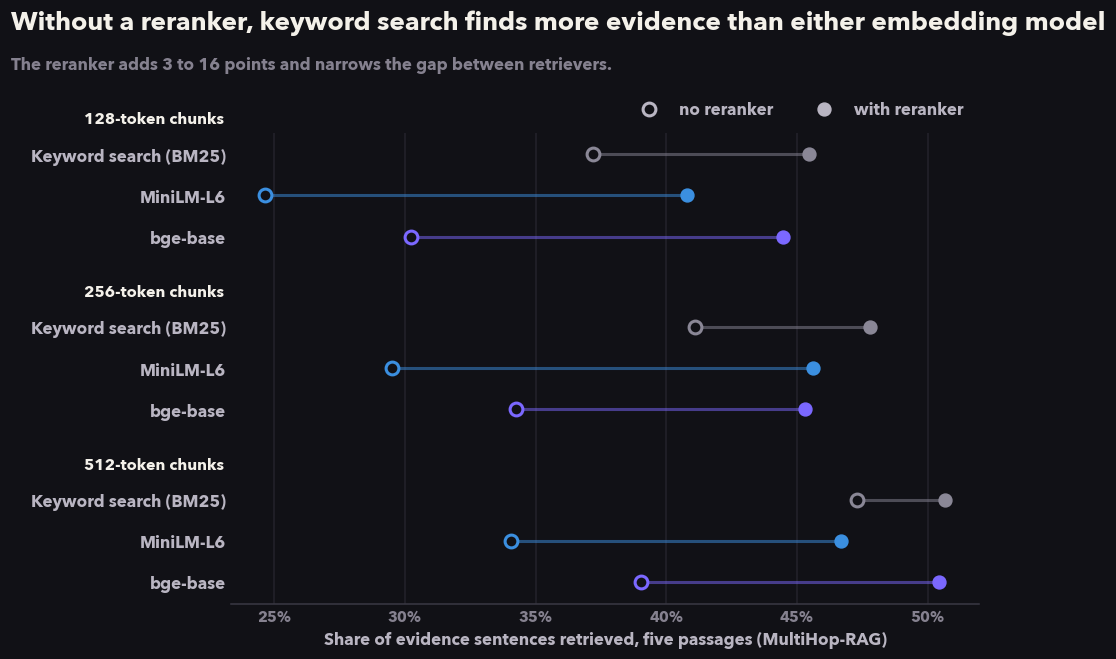

In [3]:
k5 = grid_only(mhr[mhr["k"] == 5])
off = k5[~k5["rerank"]].groupby(["chunk", "retriever"])["evidence_recall"].mean().unstack()
on = k5[k5["rerank"]].groupby(["chunk", "retriever"])["evidence_recall"].mean().unstack()
bm25_wins = bool((off["bm25"] >= off[["minilm", "bge-base"]].max(axis=1)).all())
print(f"Keyword search finds the most evidence at every chunk size without the reranker: {bm25_wins}")
print(f"Spread between best and worst retriever, average over chunk sizes: "
      f"{(off.max(axis=1) - off.min(axis=1)).mean():.1%} without the reranker, "
      f"{(on.max(axis=1) - on.min(axis=1)).mean():.1%} with it")

fig, ax = plt.subplots(figsize=(10, 6.2))
dot_plot(mhr, "evidence_recall", 5, ax, "Share of evidence sentences retrieved, five passages (MultiHop-RAG)")
gain = (on - off).stack()
title = ("Without a reranker, keyword search finds more evidence than either embedding model"
         if bm25_wins else "The reranker adds more evidence than any choice of retriever")
style.headline(fig, title,
               f"The reranker adds {gain.min() * 100:.0f} to {gain.max() * 100:.0f} points and narrows the gap between retrievers.")
fig.subplots_adjust(top=0.8, left=0.22)
style.save(fig, "retrieval_multihop")
plt.show()

Why does keyword search do so well here? MultiHop-RAG questions are long and packed with exact names: people, companies, and the news outlet each fact comes from. Keyword search rewards exactly that. It also costs nothing to run and needs no model.

In [4]:
sources = load_corpus("multihop_rag")["source"].unique()
sampled = load_questions("multihop_rag").set_index("qid").loc[mhr["qid"].unique()]
print(f"Answerable sampled questions that name a news outlet: {sampled['question'].map(lambda q: any(s in q for s in sources)).mean():.0%}")
print(f"Median words per question: {sampled['question'].str.split().map(len).median():.0f}")

Answerable sampled questions that name a news outlet: 99%
Median words per question: 45


### Each choice, averaged over all the others

Each row compares one choice with its alternative across every other setting in the grid, question by question.

In [5]:
mhr_effects = effects(mhr, "evidence_recall")
show_effects(mhr_effects)

,difference,low,high
Add the reranker,+10.0 pts,+8.2 pts,+11.8 pts
bge-base instead of keyword search,-4.4 pts,-6.2 pts,-2.5 pts
MiniLM instead of keyword search,-8.1 pts,-10.2 pts,-6.1 pts
512-token chunks instead of 128,+8.1 pts,+6.0 pts,+10.3 pts
10 passages instead of 3,+18.2 pts,+16.9 pts,+19.6 pts


Largest gains: 10 passages instead of 3 +18.2, Add the reranker +10.0, 512-token chunks instead of 128 +8.1


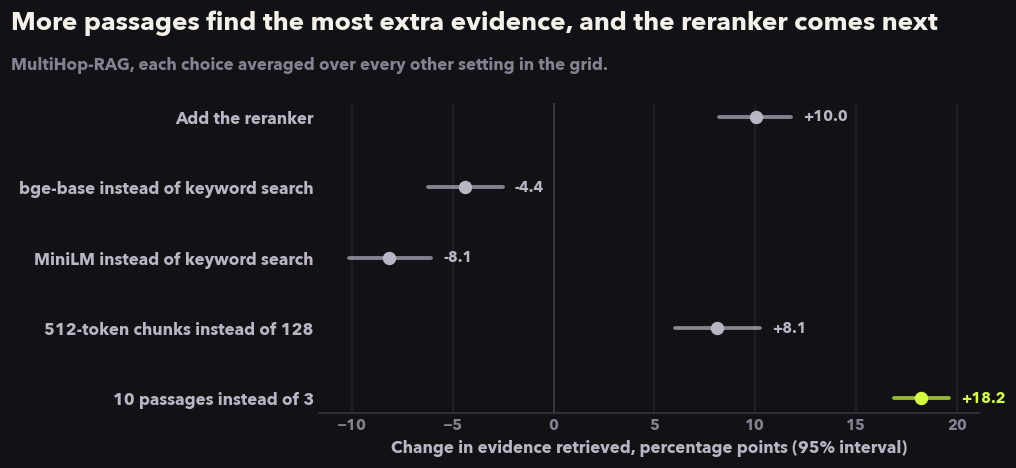

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
effect_plot(mhr_effects, ax, "Change in evidence retrieved, percentage points (95% interval)")
ranked = mhr_effects["difference"].sort_values(ascending=False)
print("Largest gains:", ", ".join(f"{label} {points(x)}" for label, x in ranked.head(3).items()))
title = ("More passages find the most extra evidence, and the reranker comes next"
         if list(ranked.index[:2]) == ["10 passages instead of 3", "Add the reranker"]
         else f"{ranked.index[0]} finds the most extra evidence")
style.headline(fig, title, "MultiHop-RAG, each choice averaged over every other setting in the grid.")
fig.subplots_adjust(top=0.78, left=0.3)
style.save(fig, "retrieval_effects_multihop")
plt.show()

Ten passages instead of three find 18 more points of evidence, and 512-token chunks instead of 128 find 8 more, but both do it by putting more text in the prompt, which notebook 05 prices. The reranker adds 10 points without making the prompt any longer; its cost is a second model call per query. Swapping keyword search for an embedding model loses evidence on this dataset.

### Finding everything is rare

Multi-hop questions need every piece of evidence, often from different articles. The share of questions where **all** of it was retrieved:

In [7]:
all_found = grid_only(mhr).groupby(["k", "rerank"])["all_evidence"].mean().unstack("rerank")
all_found.columns = ["no reranker", "with reranker"]
best_all = grid_only(mhr).groupby(["chunk", "retriever", "rerank", "k"])["all_evidence"].mean()
print(f"Best configuration finds all the evidence for {best_all.max():.0%} of questions")
all_found.style.format("{:.0%}")

Best configuration finds all the evidence for 36% of questions


,no reranker,with reranker
k,,
3,6%,14%
5,12%,22%
10,22%,28%


Even the best configuration retrieves every evidence sentence for only 36% of questions. If answer accuracy turns out much higher than that, the model is answering from partial evidence or from what it already knows, which is exactly what notebook 04 checks.

### By question type

In [8]:
by_type = grid_only(mhr).groupby(["type", "rerank"])["evidence_recall"].mean().unstack("rerank")
by_type.columns = ["no reranker", "with reranker"]
by_type.style.format("{:.0%}")

,no reranker,with reranker
type,,
comparison,45%,58%
inference,28%,38%
temporal,36%,42%


## 2. Two embedding-model questions

**Is the 256-token limit in all-MiniLM-L6-v2 a trap?** MiniLM cuts every chunk at 256 tokens, so with 512-token chunks it ignores the second half of most chunks. bge-small is the closest comparison: the same size of vector, similar speed, and no cut until 512. If truncation hurt, MiniLM's gap behind bge-small would grow at 512.

In [9]:
TABLES = {"multihop_rag": mhr, "natural_questions": nq} if len(nq) else {"multihop_rag": mhr}
plain = {name: table[~table["rerank"]] for name, table in TABLES.items()}
truncation = pd.concat({DATASETS[name]: pd.DataFrame({f"{size} tokens": contrast(t[t["chunk"] == size], MEASURE[name], "retriever", "minilm", "bge-small")
                                                      for size in CHUNK_SIZES}).T
                        for name, t in plain.items()})
truncation.index.names = ["", "MiniLM minus bge-small"]
display(show_effects(truncation))

# Does the gap grow from 256 to 512 tokens? Same questions, so the difference of differences is paired too.
for name, t in plain.items():
    gap = t[t["retriever"].isin(["minilm", "bge-small"])].groupby(["qid", "chunk", "retriever"])[MEASURE[name]].mean().unstack("retriever")
    gap = (gap["minilm"] - gap["bge-small"]).unstack("chunk")
    growth = (gap[512] - gap[256]).to_numpy()
    low, high = interval(bootstrap_means(growth, seed=0)[:, 0])
    print(f"{DATASETS[name]}: change in MiniLM's gap from 256 to 512 tokens {points(growth.mean())} points (95% interval {points(low)} to {points(high)})")

MultiHop-RAG: change in MiniLM's gap from 256 to 512 tokens -3.7 points (95% interval -6.7 to -0.8)
Natural Questions: change in MiniLM's gap from 256 to 512 tokens -0.8 points (95% interval -4.8 to +3.0)


**Does the bigger bge model pay off?** bge-base has twice the vector size of bge-small and takes about twice as long to embed a corpus.

In [10]:
size_effect = pd.DataFrame({DATASETS[name]: contrast(t, MEASURE[name], "retriever", "bge-base", "bge-small") for name, t in plain.items()}).T
size_effect.index.name = "bge-base minus bge-small"
show_effects(size_effect)

,difference,low,high
bge-base minus bge-small,,,
MultiHop-RAG,-0.8 pts,-2.3 pts,+0.8 pts
Natural Questions,-0.2 pts,-2.1 pts,+1.7 pts


MiniLM trails bge-small at every chunk size on both datasets. Its gap grows at 512 tokens on MultiHop-RAG, by about 4 points (95% interval 0.8 to 6.7), but not measurably on Natural Questions (0.8 points, interval −3.0 to +4.8). So the cut costs something, but it is not the main problem: MiniLM is behind even at 128 tokens, where nothing is cut. And the bigger bge model finds no more than the small one on either dataset (−0.8 and −0.2 points, both intervals spanning zero), so the small model does the same job at half the embedding cost.

## 3. Natural Questions: does the pattern hold?

Natural Questions are short, real search queries ("who sings ..."), not long questions full of names. That should favour embedding models over keyword search.

Both embedding models beat keyword search at every chunk size without the reranker: True
The reranker helps keyword search at every chunk size: True
The reranker's effect on bge-base at 512 tokens: -9.0 points


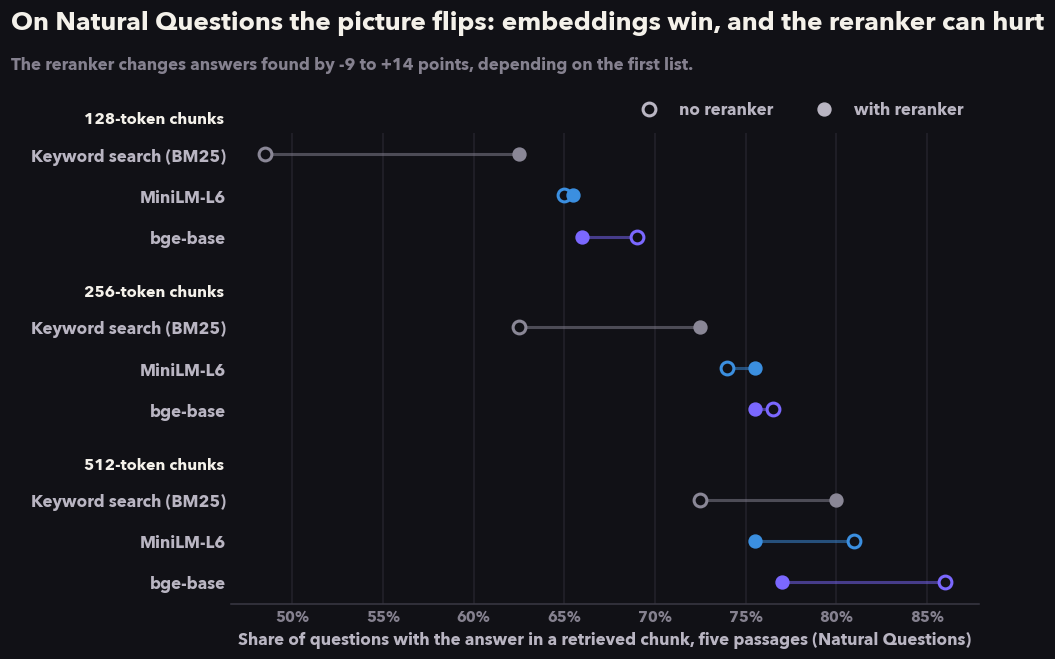

In [11]:
fig, ax = plt.subplots(figsize=(10, 6.2))
dot_plot(nq, "answer_hit", 5, ax, "Share of questions with the answer in a retrieved chunk, five passages (Natural Questions)")
nq_off = grid_only(nq[(nq["k"] == 5) & ~nq["rerank"]]).groupby(["chunk", "retriever"])["answer_hit"].mean().unstack()
nq_on = grid_only(nq[(nq["k"] == 5) & nq["rerank"]]).groupby(["chunk", "retriever"])["answer_hit"].mean().unstack()
nq_gain = (nq_on - nq_off).stack()
embeddings_win = bool((nq_off["bm25"] < nq_off[["minilm", "bge-base"]].min(axis=1)).all())
helps_bm25 = bool((nq_gain.xs("bm25", level="retriever") > 0).all())
hurts_best = float((nq_on - nq_off).loc[512, "bge-base"])
print(f"Both embedding models beat keyword search at every chunk size without the reranker: {embeddings_win}")
print(f"The reranker helps keyword search at every chunk size: {helps_bm25}")
print(f"The reranker's effect on bge-base at 512 tokens: {points(hurts_best)} points")
title = ("On Natural Questions the picture flips: embeddings win, and the reranker can hurt"
         if embeddings_win and helps_bm25 and hurts_best < 0 else "On Natural Questions the retriever matters more than the reranker")
style.headline(fig, title,
               f"The reranker changes answers found by {nq_gain.min() * 100:+.0f} to {nq_gain.max() * 100:+.0f} points, depending on the first list.")
fig.subplots_adjust(top=0.8, left=0.22)
style.save(fig, "retrieval_nq")
plt.show()

Short search queries suit embedding models, and the gap to keyword search is large. The reranker behaves differently too: it lifts keyword search's weaker lists at every chunk size, but reorders bge-base's already good lists for the worse, most of all with 512-token chunks.

Is that a quirk of the measure, which only credits chunks from the gold Wikipedia page? If the reranker promoted chunks from other pages that also contain the answer, it would look worse than it is. Counting a hit on any page:

In [12]:
nq_corpus = load_corpus("natural_questions")
nq_text = dict(zip(nq_corpus["doc_id"], nq_corpus["text"]))
nq_questions = load_questions("natural_questions").set_index("qid")
CACHE = ROOT / "cache" / "natural_questions"

def any_page_check(size, key, k=5):
    chunks = pd.read_parquet(CACHE / f"chunks_{size}.parquet")
    row = {}
    for reranked in [False, True]:
        ranked = pd.read_parquet(CACHE / f"{'rerank' if reranked else 'top'}_{key}_{size}.parquet")
        lists = ranked.sort_values(["qid", "rank"]).groupby("qid")["chunk"].apply(list)
        hit, gold_share = [], []
        for qid in nq["qid"].unique():
            top = chunks.iloc[lists[qid][:k]]
            hit.append(answer_in_texts(nq_questions.loc[qid, "answers"], [nq_text[d][s:e] for d, s, e in top[["doc_id", "start", "end"]].itertuples(index=False)]))
            gold_share.append((top["doc_id"] == nq_questions.loc[qid, "gold"][0]["doc_id"]).mean())
        label = "with reranker" if reranked else "no reranker"
        row[f"answer on any page, {label}"] = np.mean(hit)
        row[f"chunks from the gold page, {label}"] = np.mean(gold_share)
    return row

check = pd.DataFrame({f"{style.RETRIEVER_LABELS[key]}, {size} tokens": any_page_check(size, key)
                      for size in [128, 512] for key in ["bm25", "bge-base"]}).T
check.style.format("{:.0%}")

,"answer on any page, no reranker","chunks from the gold page, no reranker","answer on any page, with reranker","chunks from the gold page, with reranker"
"Keyword search (BM25), 128 tokens",54%,63%,68%,66%
"bge-base, 128 tokens",74%,79%,70%,66%
"Keyword search (BM25), 512 tokens",76%,59%,84%,61%
"bge-base, 512 tokens",88%,70%,83%,52%


The loss is real. Counting answers on any page, the reranker still lowers bge-base at 512 tokens, and the share of chunks from the right page drops sharply: it swaps good chunks from the right article for plausible-looking ones from others. A reranker is not a free upgrade. It helps a weak first list and can hurt a strong one, so it has to be tested on the data it will run on.

### Each choice, on both datasets

In [13]:
nq_effects = effects(nq, "answer_hit")
both = pd.concat({"MultiHop-RAG": mhr_effects["difference"], "Natural Questions": nq_effects["difference"]}, axis=1)
both.style.format(lambda x: f"{points(x)} pts")

,MultiHop-RAG,Natural Questions
Add the reranker,+10.0 pts,+2.1 pts
bge-base instead of keyword search,-4.4 pts,+8.9 pts
MiniLM instead of keyword search,-8.1 pts,+6.8 pts
512-token chunks instead of 128,+8.1 pts,+16.1 pts
10 passages instead of 3,+18.2 pts,+15.1 pts


In [14]:
show_effects(nq_effects)

,difference,low,high
Add the reranker,+2.1 pts,0.0 pts,+4.4 pts
bge-base instead of keyword search,+8.9 pts,+5.6 pts,+12.3 pts
MiniLM instead of keyword search,+6.8 pts,+3.9 pts,+10.2 pts
512-token chunks instead of 128,+16.1 pts,+12.2 pts,+20.2 pts
10 passages instead of 3,+15.1 pts,+13.1 pts,+17.4 pts


## 4. What retrieval costs in time

Search and reranking were timed for 50 questions per dataset, one query at a time on an Apple M4 after a warm-up, as a live system would run them. Reranking time depends on the length of the 30 chunks, not on which retriever found them, so it is timed once per chunk size. Notebook 05 turns these times into cost per answer.

In [15]:
timing = pd.read_csv(RESULTS_DIR / "timing.csv")
timing["dataset"] = timing["dataset"].map(DATASETS)
search = timing[timing["step"] == "search"].pivot_table(index=["dataset", "retriever"], columns="chunk", values="seconds_per_query") * 1000
rerank_time = timing[timing["step"] == "rerank"].pivot_table(index="dataset", columns="chunk", values="seconds_per_query")
print("Search, milliseconds per query")
display(search.round(0).astype(int))
print("Reranking 30 chunks, seconds per query")
display(rerank_time.round(2))

Search, milliseconds per query


chunk                        128  256  512
dataset           retriever               
MultiHop-RAG      bge-base    24   20   19
                  bge-small   18   15   15
                  bm25        66   27   13
                  minilm      13    6    7
Natural Questions bge-base    22   19   18
                  bge-small   16   12   11
                  bm25       251  146   70
                  minilm      14    8    8

Reranking 30 chunks, seconds per query


chunk,128,256,512
dataset,,,
MultiHop-RAG,0.55,1.11,1.83
Natural Questions,0.50,1.02,1.80


Embedding search takes 6 to 24 milliseconds a query. Keyword search is slower here, up to 251 milliseconds, because the rank_bm25 library scores every chunk in plain Python, which is also why it slows down as chunks get smaller and more numerous. A search engine with an inverted index would be far faster, so these keyword times overstate its cost.

Reranking is the slow step: about half a second for 30 chunks of 128 tokens and 1.8 seconds at 512, the same on both datasets, because the reranker reads every chunk in full.

## What this tells us

- **The best retriever depends on the questions.** On MultiHop-RAG's long questions full of names, keyword search beats both embedding models without a reranker (bge-base finds 4.4 points less evidence). On Natural Questions' short search queries, bge-base beats keyword search by 8.9 points.
- **A reranker is not a free upgrade.** It adds 10.0 points on MultiHop-RAG but only 2.1 on Natural Questions, with an interval touching zero. It lifts weak first lists and cut bge-base's strong 512-token list by 9 points.
- **More text finds more.** Ten passages instead of three add 18.2 and 15.1 points; 512-token chunks instead of 128 add 8.1 and 16.1. Both make the prompt longer, so notebook 05 has to show whether the extra is worth paying for.
- **A small embedding model is enough.** bge-small matches bge-base on both datasets. MiniLM's 256-token cut costs about 4 points at 512 tokens on MultiHop-RAG, but MiniLM trails even where nothing is cut.
- **Multi-hop retrieval rarely finds everything.** The best configuration retrieves all the evidence for only 36% of MultiHop-RAG questions.
- **Reranking is the slow step.** Searching takes milliseconds; reranking 30 chunks takes about half a second at 128 tokens and 1.8 seconds at 512, so the reranker has to earn its place in time as well as money.

These are retrieval scores, not answers. Whether they predict what the model gets right is the subject of notebook 04. Next: [notebook 03](03_answers.ipynb) measures answer accuracy for the 24 configurations that get answers.